In [1]:

import numpy as np
import pandas as pd

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

import kagglehub


/kaggle/input/datasets/bahaabashtawi/dataset-4h-m/XAU_4h_data.csv


In [2]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

def load_and_preprocess_data():
    df = pd.read_csv('XAU_4h_data.csv', sep=';')
    df = df.dropna().head(2000)  
    X = df[['Open']].values
    y = df['Close'].values
    
   
    poly = PolynomialFeatures(degree=2)
    X_poly = poly.fit_transform(X)
    
   
    scaler_X = StandardScaler()
    X_scaled = scaler_X.fit_transform(X_poly)
    
    scaler_y = StandardScaler()
    y_scaled = scaler_y.fit_transform(y.reshape(-1, 1)).flatten()
    
    return X_scaled, y_scaled

RMSProp Final Cost: 0.0024559692539171335
RMSProp Final Theta: [0.         0.52507299 0.46211137]


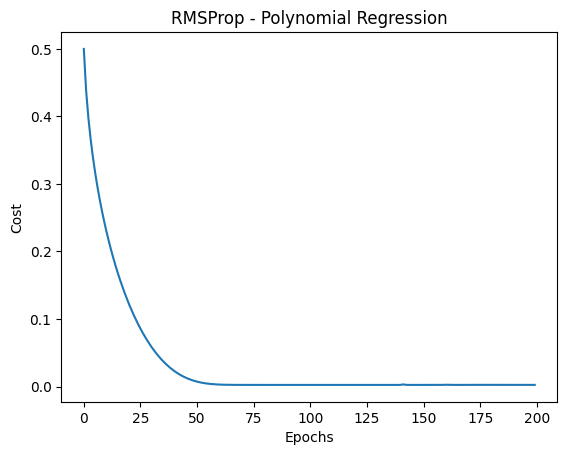

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
import glob

def load_and_preprocess_data():
    csv_files = glob.glob('/kaggle/input/**/XAU_4h_data.csv', recursive=True)
    file_path = csv_files[0] if csv_files else 'XAU_4h_data.csv'
    
    df = pd.read_csv(file_path, sep=';')
    df = df.dropna().head(2000)  
    X = df[['Open']].values
    y = df['Close'].values
    
    poly = PolynomialFeatures(degree=2)
    X_poly = poly.fit_transform(X)
    
    scaler_X = StandardScaler()
    X_scaled = scaler_X.fit_transform(X_poly)
    
    scaler_y = StandardScaler()
    y_scaled = scaler_y.fit_transform(y.reshape(-1, 1)).flatten()
    
    return X_scaled, y_scaled

X, y = load_and_preprocess_data()
m, n = X.shape

theta = np.zeros(n)
learning_rate = 0.01
beta = 0.9
epsilon = 1e-8
s = np.zeros(n)
epochs = 200
costs = []

for epoch in range(epochs):
    predictions = np.dot(X, theta)
    errors = predictions - y
    cost = (1 / (2 * m)) * np.sum(errors ** 2)
    costs.append(cost)
    
    gradient = (1 / m) * np.dot(X.T, errors)
    
    s = beta * s + (1 - beta) * (gradient ** 2)
    theta -= (learning_rate / (np.sqrt(s) + epsilon)) * gradient

print("RMSProp Final Cost:", costs[-1])
print("RMSProp Final Theta:", theta)

plt.plot(costs)
plt.title("RMSProp - Polynomial Regression")
plt.xlabel("Epochs")
plt.ylabel("Cost")
plt.savefig("rmsprop_cost.png")
plt.show()